# Module 3 — Reduced Order Modelling (ROM)

---
## 1. 1D bar

A bar of unit length carries a heat flux $q$. Fourier's law (sign dropped, unit length):

$$q = k\,\Delta T \quad\Longrightarrow\quad \Delta T = \frac{q}{k}$$

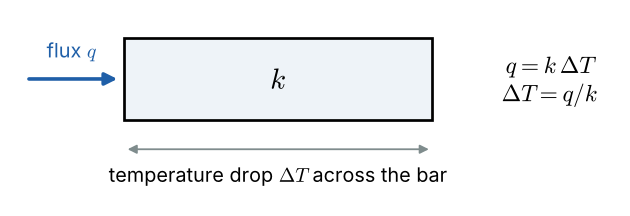

*1D bar: flux q through conductivity k gives a temperature drop ΔT*

Take $q = 1$ and two materials:

| Material | $k$ | $\Delta T$ |
|---|---|---|
| 1 | $k_1 = 100$ | $\Delta T_1 = 0.01$ |
| 2 | $k_2 = 1$ | $\Delta T_2 = 1$ |

**Question.** Both materials have already been "solved". For a new material with
$k = \dfrac{k_1+k_2}{2} = 50.5$, can we just average the two answers?

- Interpolated output: $\dfrac{\Delta T_1 + \Delta T_2}{2} = \dfrac{0.01 + 1}{2} = 0.505$
- Exact output: $\Delta T = \dfrac{1}{50.5} = 0.0198$

The interpolated value is about **25 times too large**.

**Why.** $\Delta T(k) = q/k$ is a hyperbola. Linear interpolation follows the **chord** between the two known points, while the true value lies on the **curve**, far below the chord.

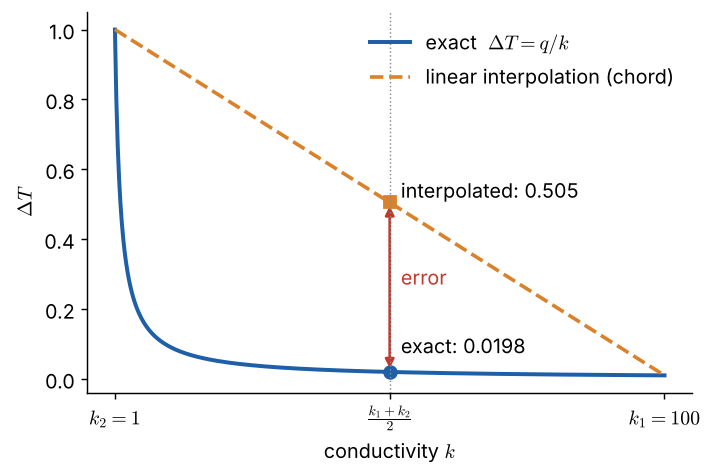

*ΔT vs k: the true curve and the interpolation chord*

---
## 2. 2D: a two-layer composite and its effective conductivity

Two layers with volume fractions $\phi$ (material $a$, conductivity $k_a$) and $1-\phi$ (material $b$, conductivity $k_b$), with $0 \le \phi \le 1$.

The **effective conductivity** is defined from averages over the composite:

$$k_{\text{eff}} = \frac{\langle q \rangle}{\langle g \rangle}, \qquad g = \text{temperature gradient}$$

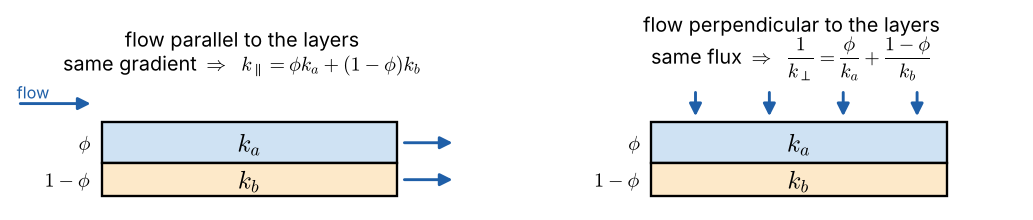

*Two-layer composite: flow along the layers (left) and across them (right)*

### Flow parallel to the layers
Both layers see the **same gradient** $g$. The fluxes are $k_a g$ and $k_b g$, and they add by volume fraction:

$$\langle q\rangle = \big(\phi k_a + (1-\phi)k_b\big)g \quad\Longrightarrow\quad k_\parallel = \phi\,k_a + (1-\phi)\,k_b \qquad \text{}$$

### Flow perpendicular to the layers
Both layers carry the **same flux** $q$. The gradients are $q/k_a$ and $q/k_b$, and they add by volume fraction:

$$\langle g\rangle = \Big(\frac{\phi}{k_a} + \frac{1-\phi}{k_b}\Big) q \quad\Longrightarrow\quad \frac{1}{k_\perp} = \frac{\phi}{k_a} + \frac{1-\phi}{k_b} \qquad \text{}$$

### Example
$k_a = 400$, $k_b = 1$, $\phi = 0.5$:

$$k_\parallel = 0.5(400) + 0.5(1) = 200.5, \qquad \frac{1}{k_\perp} = \frac{0.5}{400} + \frac{0.5}{1} = 0.50125 \;\Rightarrow\; k_\perp \approx 1.995 \approx 2$$

The same composite conducts about **100 times better** along the layers than across them: layering creates strong **anisotropy**. Always $k_\perp \le k_\parallel$, and these are the two extreme bounds for any arrangement of the two materials.

---
## 3. Rotated laminate: the conductivity tensor $K(\theta)$

Rotate the layers by an angle $\theta$. Let $n$ be the unit vector **along the layers** and $t$ the unit vector **across the layers**:

$$n = (\cos\theta,\ \sin\theta), \qquad t = (-\sin\theta,\ \cos\theta)$$

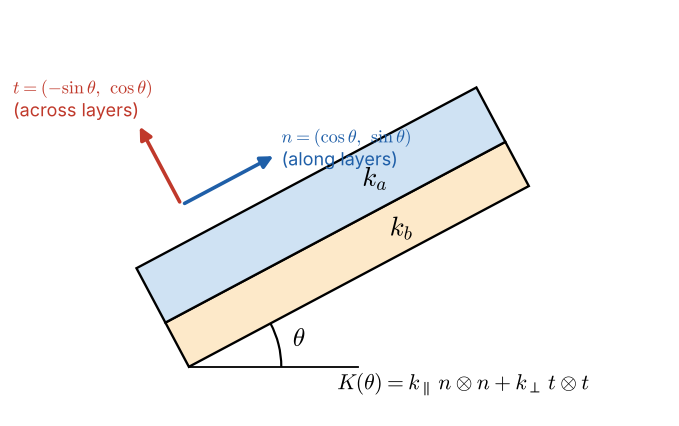

*Laminate rotated by θ, with n along and t across the layers*

The laminate conducts with $k_\parallel$ along $n$ and $k_\perp$ along $t$, so the conductivity tensor is

$$K(\theta) = k_\parallel\, n\otimes n + k_\perp\, t\otimes t, \qquad q = -K(\theta)\,g, \qquad g = -K^{-1}(\theta)\,q$$

Here $g = \nabla T$; heat flows down the temperature gradient, hence the minus sign.

### Inverse
$n$ and $t$ are orthonormal, so $n\otimes n$ and $t\otimes t$ are complementary projectors ($n\otimes n + t\otimes t = I$). Inverting $K$ simply inverts the two conductivities:

$$K^{-1}(\theta) = \frac{1}{k_\parallel}\, n\otimes n + \frac{1}{k_\perp}\, t\otimes t$$

### Writing out the projectors
With $c = \cos\theta$, $s = \sin\theta$:

$$n\otimes n = nn^{\top} = \begin{bmatrix} c \\ s \end{bmatrix}\begin{bmatrix} c & s \end{bmatrix} = \begin{bmatrix} c^2 & cs \\ cs & s^2 \end{bmatrix}, \qquad
t\otimes t = tt^{\top} = \begin{bmatrix} -s \\ c \end{bmatrix}\begin{bmatrix} -s & c \end{bmatrix} = \begin{bmatrix} s^2 & -cs \\ -cs & c^2 \end{bmatrix}$$

### Double-angle form
Use $c^2 = \tfrac12(1+\cos 2\theta)$, $s^2 = \tfrac12(1-\cos2\theta)$, $cs = \tfrac12\sin2\theta$:

$$n\otimes n = \frac12\begin{bmatrix}1+\cos2\theta & \sin2\theta\\ \sin2\theta & 1-\cos2\theta\end{bmatrix} = \tfrac12\big(I + C(\theta)\big), \qquad
t\otimes t = \tfrac12\big(I - C(\theta)\big)$$

$$C(\theta) = \begin{bmatrix} \cos2\theta & \sin2\theta \\ \sin2\theta & -\cos2\theta \end{bmatrix}$$

Substituting and collecting the $I$ and $C$ terms:

$$K^{-1}(\theta) = \Big(\frac{1}{2k_\parallel} + \frac{1}{2k_\perp}\Big) I + \Big(\frac{1}{2k_\parallel} - \frac{1}{2k_\perp}\Big) C(\theta)$$

$$\boxed{K^{-1}(\theta) = \alpha\, I + \beta\, C(\theta), \qquad
\alpha = \frac{1}{2k_\parallel} + \frac{1}{2k_\perp}, \qquad
\beta = \frac{1}{2k_\parallel} - \frac{1}{2k_\perp}}$$

---
## 4. The response $g(\theta)$ traces a circle

Fix the applied flux $q = |q|(\cos\psi,\ \sin\psi)$ and vary only the laminate angle $\theta$:

$$g(\theta) = -K^{-1}(\theta)\,q = -\alpha\,q - \beta\,|q|\; C(\theta)\begin{bmatrix}\cos\psi\\ \sin\psi\end{bmatrix}$$

Using the angle-difference identities:

$$C(\theta)\begin{bmatrix}\cos\psi\\ \sin\psi\end{bmatrix}
= \begin{bmatrix}\cos2\theta\cos\psi + \sin2\theta\sin\psi \\ \sin2\theta\cos\psi - \cos2\theta\sin\psi\end{bmatrix}
= \begin{bmatrix}\cos(2\theta-\psi) \\ \sin(2\theta-\psi)\end{bmatrix}$$

$$\boxed{g(\theta) = -\alpha\,q - \beta\,|q| \begin{bmatrix}\cos(2\theta-\psi) \\ \sin(2\theta-\psi)\end{bmatrix}}$$

### Geometry
As $\theta$ varies, $g$ lies on a **circle** with

- **centre** $-\alpha\,q$ — on the opposite side of the origin from $q$, because heat flows *down* the temperature gradient
- **radius** $R = |\beta|\,|q|$ (a reflection does not change length, $|C q| = |q|$)
- angle on the circle $= 2\theta - \psi$, so one full turn as $\theta$ goes from $0$ to $\pi$ ($\theta$ and $\theta + \pi$ describe the same laminate).

With $\psi = 45^\circ$, $q$ points into the first quadrant, so the centre lies in the third quadrant.

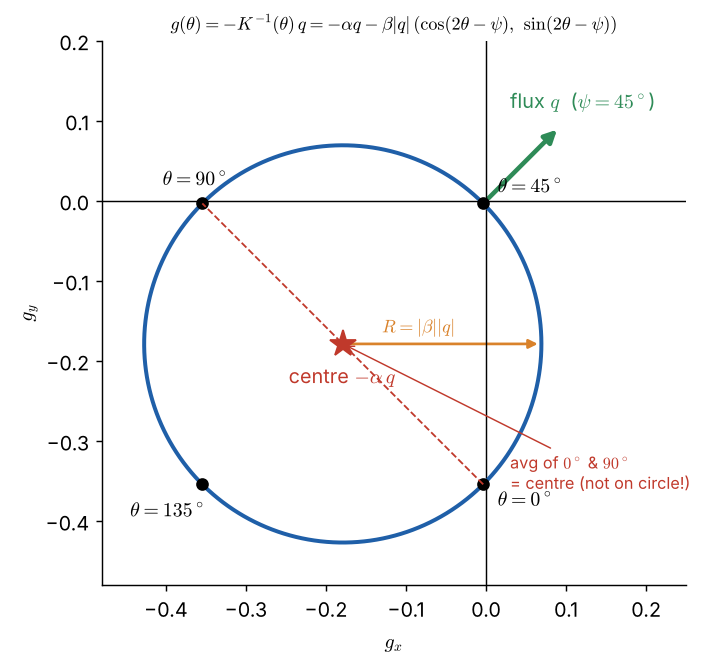

*Locus of g as θ varies (ψ = 45°): a circle in the third quadrant with centre −αq and radius |β||q|*

### Special points ($\psi = 45^\circ$, $|q| = 1$)
- $\theta = 45^\circ$: flux **along** the layers ($q \parallel n$), so $g = -q/k_\parallel$ — tiny, almost at the origin.
- $\theta = 135^\circ$: flux **across** the layers ($q \parallel t$), so $g = -q/k_\perp$ — the largest response, farthest from the origin.
- $\theta = 0^\circ$: $g = -\tfrac{1}{\sqrt2}\big(\tfrac{1}{k_\parallel},\ \tfrac{1}{k_\perp}\big)$, almost on the negative $g_y$-axis.
- $\theta = 90^\circ$: $g = -\tfrac{1}{\sqrt2}\big(\tfrac{1}{k_\perp},\ \tfrac{1}{k_\parallel}\big)$, almost on the negative $g_x$-axis.

The closest point of the circle to the origin is at distance $|q|/k_\parallel$ and the farthest at $|q|/k_\perp$.

### "Average of 0° and 90° will be the centre — but it is absurd"
Since $C(90^\circ) = -C(0^\circ)$,

$$\tfrac12\big(g(0^\circ) + g(90^\circ)\big) = -\alpha q - \tfrac12\beta\big(C(0^\circ) + C(90^\circ)\big)q = -\alpha q$$

which is exactly the **centre**. That point is a distance $R$ from *every* point of the circle: it is the response of **no** laminate orientation. Averaging snapshots throws away exactly the part $\beta C(\theta) q$ that carries the anisotropy.

### Interpolation error on a finer $\theta$ grid
Sample $\theta$ with step $h = \pi/m$ (the "increment for theta"). Two neighbouring samples are separated by an angle $2h$ **on the circle**. Linear interpolation takes the midpoint of the chord, while the true value at the middle angle lies on the arc.

$$e = R\,(1 - \cos h) \approx \frac{R\,h^2}{2} \qquad (h \to 0)$$

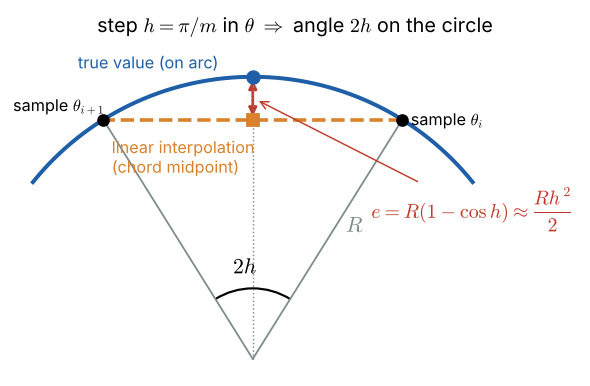

*Chord vs arc between two neighbouring θ samples*

So interpolation in $\theta$ does converge, but only at second order, $O(h^2)$: halving the step only quarters the error, and accuracy requires many snapshots. Every new parameter dimension multiplies that cost.

---
## 5. The right combination of snapshots — the reduced-basis idea

Simplified case from class: $k_\perp = 1$, $k_\parallel = k \gg 1$, and the same flux as the sketch, $q = \tfrac{1}{\sqrt2}(1, 1)$ ($\psi = 45^\circ$).

### Snapshots
At $\theta = 0^\circ$, $K^{-1} = \operatorname{diag}(1/k,\ 1)$; at $\theta = 90^\circ$, $K^{-1} = \operatorname{diag}(1,\ 1/k)$. With $g = -K^{-1}q$:

$$g(0^\circ) = -\tfrac{1}{\sqrt2}\Big(\tfrac1k,\ 1\Big), \qquad g(90^\circ) = -\tfrac{1}{\sqrt2}\Big(1,\ \tfrac1k\Big)$$

### Naive average
$$\bar g = \tfrac12\big(g(0^\circ)+g(90^\circ)\big) = -\frac{1}{2\sqrt2}\Big(1+\tfrac1k,\ 1+\tfrac1k\Big) = -\alpha\,q$$

— the centre of the circle, as in Section 4.

### True answer at 45°
Now $n = \tfrac{1}{\sqrt2}(1,1)$ is parallel to $q$, so

$$g(45^\circ) = -K^{-1}(45^\circ)\,q = -\frac{q}{k} = -\frac{1}{k\sqrt2}(1,\ 1)$$

The naive average is $\dfrac{1+k}{2}$ times too large (50.5× for $k = 100$).

### Alternative: allow any weights
Look for
$$g(45^\circ) = a\,g(0^\circ) + b\,g(90^\circ)$$

Component-wise (the common factor $-\tfrac{1}{\sqrt2}$ cancels):
$$\frac{a}{k} + b = \frac1k, \qquad a + \frac{b}{k} = \frac1k$$

By symmetry $a = b$, so $a\big(1 + \tfrac1k\big) = \tfrac1k$:

$$\boxed{a = b = \frac{1}{1+k}}$$

### Interpretation
The correct answer **is** in the span of the two snapshots — the interpolation weights $(\tfrac12, \tfrac12)$ were simply the wrong coefficients. The solution set (the circle) is curved, but its **linear span** still contains the answer.

---
## 6. Two parameters: volume fraction $\phi$ and angle $\theta$

Now treat the composite as a black box with inputs $(\theta, \phi)$ and output $g$:

$$(\theta,\ \phi) \;\longrightarrow\; \boxed{\text{laminate}} \;\longrightarrow\; g$$

$$g(\theta, \phi) = -\alpha(\phi)\,q - \beta(\phi)\,C(\theta)\,q$$

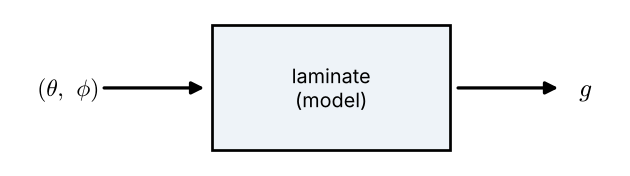

*The composite as a black box: parameters in, response out*

where $\alpha(\phi), \beta(\phi)$ are built from $k_\parallel(\phi)$ and $k_\perp(\phi)$ of Section 2, and $C(\theta)$ is the $\cos2\theta, \sin2\theta$ matrix.

### A family of circles
- For each fixed $\phi$: a circle with centre $-\alpha(\phi)\,q$ and radius $|\beta(\phi)|\,|q|$. **Both depend on $\phi$**, so centres and radii keep varying — a nested family of circles.
- $\phi = 0$: only material $b$; $k_\parallel = k_\perp = k_b$, so $\beta = 0$ and the circle shrinks to the single point $-q/k_b$.
- $\phi = 1$: only material $a$; the circle shrinks to the point $-q/k_a$.
- Each circle comes within $|q|/k_\parallel(\phi)$ of the origin. Because $k_\parallel$ is large for most $\phi$, all the circles nearly touch the origin.

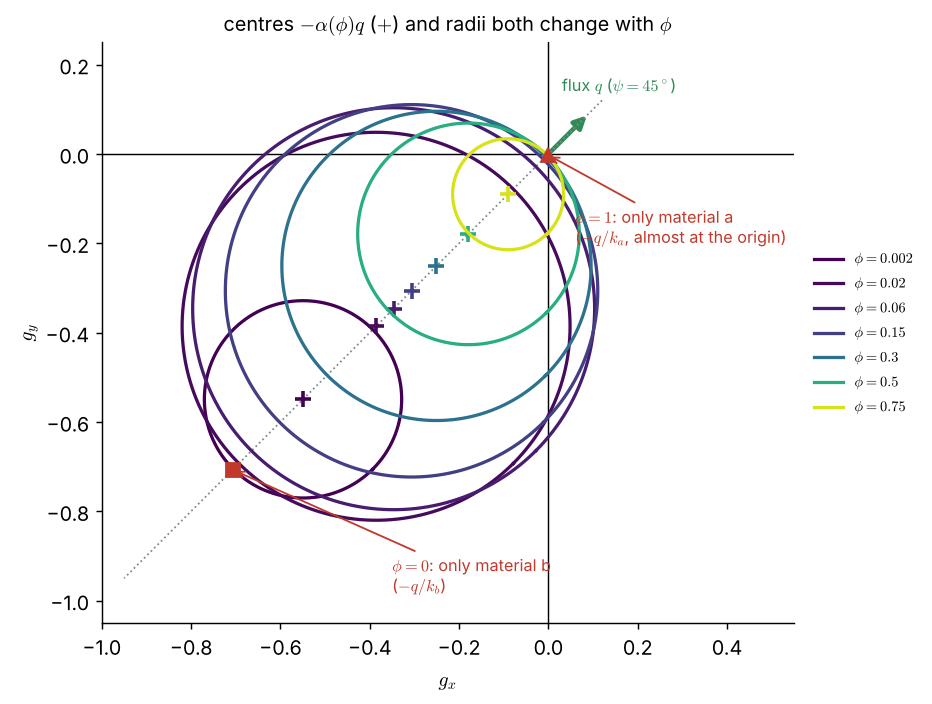

*Family of circles for different φ (flux q at ψ = 45°, as in the notes: centres run along the diagonal into the third quadrant)*

### Sampling
50 values of $\theta$ × 50 values of $\phi$ = **2500 samples**.